Title : Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following
. Pre-process the dataset
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and ridge, Lasso regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc_
Dataset link: https'/www.kaggl e.com/datasets/yasserh/uber-fares-dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("uber.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB

Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64



Duplicate Rows: 0

Statistical Summary:


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [4]:
# Remove unnecessary columns
df = df.drop(columns=['Unnamed: 0', 'key'])

# Remove rows with missing values
df = df.dropna()

# Convert pickup_datetime to datetime
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce',
    utc=True
)

# Remove rows with invalid datetime values
df = df.dropna(subset=['pickup_datetime'])

print("Dataset Shape After Basic Cleaning:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape After Basic Cleaning: (199999, 7)

Missing Values:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

Data Types:
fare_amount                      float64
pickup_datetime      datetime64[us, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object


In [5]:
# Keep only valid fares and passenger counts
df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6))
]

# Keep coordinates within a reasonable New York City region
df = df[
    df['pickup_longitude'].between(-75, -72) &
    df['dropoff_longitude'].between(-75, -72) &
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42)
]

print("Dataset Shape After Removing Invalid Values:", df.shape)

print("\nMinimum Fare:", df['fare_amount'].min())
print("Maximum Fare:", df['fare_amount'].max())
print("Passenger Counts:", sorted(df['passenger_count'].unique()))

Dataset Shape After Removing Invalid Values: (195100, 7)

Minimum Fare: 0.01
Maximum Fare: 499.0
Passenger Counts: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


Q1: 6.0
Q3: 12.5
IQR: 6.5
Lower Bound: -3.75
Upper Bound: 22.25
Number of Fare Outliers: 16708


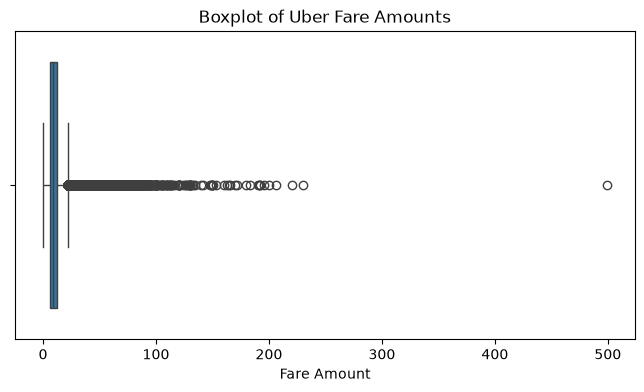

In [6]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower_bound) |
    (df['fare_amount'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Fare Outliers:", len(outliers))

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])
plt.title("Boxplot of Uber Fare Amounts")
plt.xlabel("Fare Amount")
plt.show()


Outliers handled using IQR capping.
Dataset Shape: (195100, 7)

Fare Summary After Capping:
count    195100.000000
mean         10.082801
std           5.433790
min           0.010000
25%           6.000000
50%           8.500000
75%          12.500000
max          22.250000
Name: fare_amount, dtype: float64


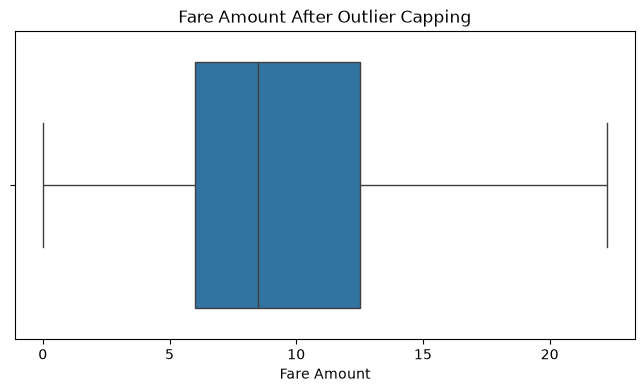

In [7]:
df['fare_amount'] = df['fare_amount'].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Outliers handled using IQR capping.")
print("Dataset Shape:", df.shape)

print("\nFare Summary After Capping:")
print(df['fare_amount'].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount After Outlier Capping")
plt.xlabel("Fare Amount")
plt.show()

Correlation with Fare Amount:
fare_amount          1.000000
pickup_longitude     0.260313
dropoff_longitude    0.255500
passenger_count      0.013702
dropoff_latitude    -0.129160
pickup_latitude     -0.136443
Name: fare_amount, dtype: float64


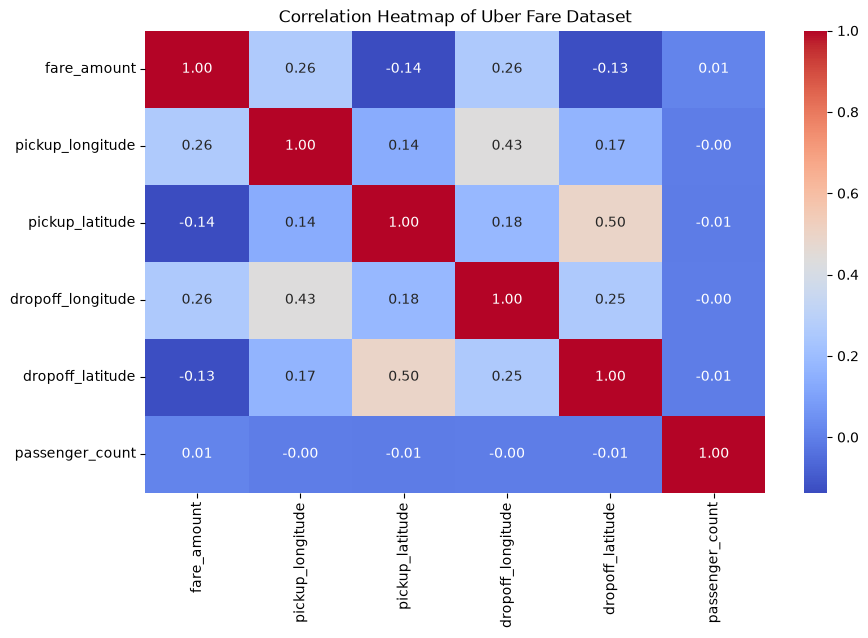

In [8]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation with Fare Amount:")
print(correlation_matrix['fare_amount'].sort_values(ascending=False))

# Plot correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Uber Fare Dataset")
plt.show()

In [9]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(row):
    lat1 = radians(row['pickup_latitude'])
    lon1 = radians(row['pickup_longitude'])

    lat2 = radians(row['dropoff_latitude'])
    lon2 = radians(row['dropoff_longitude'])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return 6371 * c

df['distance_km'] = df.apply(calculate_distance, axis=1)

print("Distance feature created successfully!")

print(df[[
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'distance_km',
    'fare_amount'
]].head())

Distance feature created successfully!
   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   distance_km  fare_amount  
0     1.683323          7.5  
1     2.457590          7.7  
2     5.036377         12.9  
3     1.661683          5.3  
4     4.475450         16.0  


In [11]:
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_month'] = df['pickup_datetime'].dt.month

print("Time-based features created successfully!")

print(df[[
    'pickup_datetime',
    'pickup_hour',
    'pickup_day',
    'pickup_month'
]].head())

Time-based features created successfully!
            pickup_datetime  pickup_hour  pickup_day  pickup_month
0 2015-05-07 19:52:06+00:00           19           7             5
1 2009-07-17 20:04:56+00:00           20          17             7
2 2009-08-24 21:45:00+00:00           21          24             8
3 2009-06-26 08:22:21+00:00            8          26             6
4 2014-08-28 17:47:00+00:00           17          28             8


In [12]:
X = df[['distance_km', 'passenger_count',
        'pickup_hour', 'pickup_day', 'pickup_month']]

y = df['fare_amount']

print("Features and target selected successfully!")
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Features and target selected successfully!
X Shape: (195100, 5)
y Shape: (195100,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and Testing Data Split Successfully!")

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)


Training and Testing Data Split Successfully!
X_train Shape: (156080, 5)
X_test Shape: (39020, 5)
y_train Shape: (156080,)
y_test Shape: (39020,)


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.01)
}

for name, model in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    print(name, "trained successfully!")

Linear Regression trained successfully!
Ridge Regression trained successfully!


Lasso Regression trained successfully!


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [16]:
for name, model in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    print("\n", name)

    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("R2 Score:", r2_score(y_test, y_pred))


 Linear Regression
MAE: 2.5252644530558768
MSE: 12.487611709055232
RMSE: 3.5337815027326225
R2 Score: 0.5741821095545275

 Ridge Regression
MAE: 2.52527062942663
MSE: 12.487612862957562
RMSE: 3.5337816659999755
R2 Score: 0.5741820702073515

 Lasso Regression
MAE: 2.527644963932536
MSE: 12.487584045524699
RMSE: 3.5337775885763807
R2 Score: 0.5741830528594996


In [17]:
# !pip install pandas numpy matplotlib seaborn scikit-learn